# Lab 2 - AlexNet préentraîné pour MNIST

Notebook Kaggle pour AlexNet avec transfert d’apprentissage. Il charge les poids ImageNet, gèle la majeure partie du réseau et ajuste le dernier bloc convolutionnel ainsi qu’une tête à 10 classes. Le meilleur checkpoint est sélectionné sur validation. Les 10 000 images test sont réservées à l’évaluation finale.

Dans Kaggle : attachez le dataset MNIST avec Add Input, choisissez Settings > Accelerator > GPU T4 x2 et activez Internet pour télécharger les poids AlexNet (~233 MB) s’ils ne sont pas en cache.

In [1]:
from pathlib import Path
import os,gzip,shutil,random,json,subprocess,sys
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset,DataLoader
from torchvision import datasets,transforms
from torchvision.models import alexnet,AlexNet_Weights
import matplotlib.pyplot as plt
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if not torch.cuda.is_available(): raise RuntimeError("Activez un GPU dans les paramètres Kaggle.")
NUM_GPUS=torch.cuda.device_count()
for i in range(NUM_GPUS): print(f"GPU {i}: {torch.cuda.get_device_name(i)}")
if NUM_GPUS<2: raise RuntimeError("Sélectionnez GPU T4 x2 pour utiliser les deux GPU.")

GPU 0: Tesla T4
GPU 1: Tesla T4


## Préparer MNIST

In [2]:
required=["train-images-idx3-ubyte","train-labels-idx1-ubyte","t10k-images-idx3-ubyte","t10k-labels-idx1-ubyte"]
files=[p for p in Path("/kaggle/input").rglob("*") if p.is_file()]
raw=Path("/kaggle/working/MNIST/raw"); raw.mkdir(parents=True,exist_ok=True)
for name in required:
    found=[p for p in files if p.name in (name,name+".gz")]
    if not found: raise FileNotFoundError(f"{name} absent; ajoutez MNIST dans Add Input.")
    src=found[0]; dst=raw/name
    if src.name.endswith(".gz"):
        with gzip.open(src,"rb") as fi,open(dst,"wb") as fo: shutil.copyfileobj(fi,fo)
    else: shutil.copy2(src,dst)

## Paramètres et jeux de données
59 000 images pour l’entraînement, 1 000 pour la validation, puis les 10 000 images test pour l’évaluation finale.

In [3]:
TRAIN_SIZE=59000
VAL_SIZE=1000
BATCH_PER_GPU=32
EPOCHS=10
PATIENCE=3
IMAGE_SIZE=96
class MNISTRGB(Dataset):
    def __init__(self,train=True,indices=None):
        self.ds=datasets.MNIST("/kaggle/working",train=train,download=False)
        self.indices=list(range(len(self.ds))) if indices is None else list(indices)
        self.tf=transforms.Compose([transforms.Resize((IMAGE_SIZE,IMAGE_SIZE),antialias=True),
            transforms.Normalize((.485,.456,.406),(.229,.224,.225))])
    def __len__(self): return len(self.indices)
    def __getitem__(self,i):
        im,y=self.ds[self.indices[i]]
        return self.tf(transforms.ToTensor()(im).repeat(3,1,1)),int(y)
g=torch.Generator().manual_seed(SEED)
perm=torch.randperm(60000,generator=g).tolist()
val_idx=perm[:VAL_SIZE]; train_idx=perm[VAL_SIZE:VAL_SIZE+TRAIN_SIZE]
train_ds=MNISTRGB(True,train_idx); val_ds=MNISTRGB(True,val_idx); test_ds=MNISTRGB(False)
train_loader=DataLoader(train_ds,batch_size=64,shuffle=True,num_workers=2,pin_memory=True)
val_loader=DataLoader(val_ds,batch_size=64,shuffle=False,num_workers=2,pin_memory=True)
test_loader=DataLoader(test_ds,batch_size=64,shuffle=False,num_workers=2,pin_memory=True)
print(f"Train {len(train_ds)} | validation {len(val_ds)} | test {len(test_ds)}")

Train 59000 | validation 1000 | test 10000


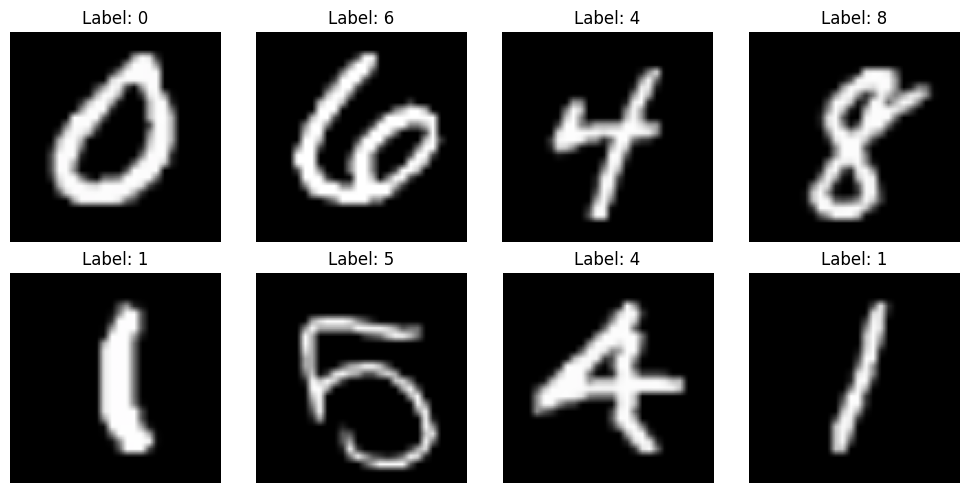

In [4]:
mean=torch.tensor([.485,.456,.406]).view(3,1,1)
std=torch.tensor([.229,.224,.225]).view(3,1,1)
xs,ys=next(iter(train_loader))
fig,axs=plt.subplots(2,4,figsize=(10,5))
for ax,x,y in zip(axs.flat,xs[:8],ys[:8]):
    ax.imshow((x*std+mean).clamp(0,1).permute(1,2,0))
    ax.set_title(f"Label: {y.item()}"); ax.axis("off")
plt.tight_layout(); plt.show()

## Charger les poids AlexNet préentraînés
Le poids ImageNet est téléchargé une fois avant le lancement sur deux GPU. Internet Kaggle est requis s’il n’est pas en cache.

In [5]:
try:
    pretrained=alexnet(weights=AlexNet_Weights.IMAGENET1K_V1)
except Exception as e:
    raise RuntimeError("Poids AlexNet indisponibles. Activez Internet Kaggle ou ajoutez les poids comme input. "+str(e))
pretrained_path="/kaggle/working/alexnet_imagenet_features.pth"
torch.save(pretrained.features.state_dict(),pretrained_path)
del pretrained
print("Poids prêts:",pretrained_path)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 213MB/s] 


Poids prêts: /kaggle/working/alexnet_imagenet_features.pth


## Fine-tuning DDP sur deux GPU
La majorité des couches préentraînées restent gelées. Seul le dernier bloc convolutionnel et la nouvelle tête sont ajustés. Dropout, weight decay et early stopping limitent le surapprentissage.

In [6]:
worker_script = r"""
import os,json,time,random
import numpy as np
import torch,torch.nn as nn,torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import Dataset,DataLoader,DistributedSampler
from torchvision import datasets,transforms
from torchvision.models import alexnet
SIZE=int(os.environ["IMAGE_SIZE"]); SEED=42
class Digits(Dataset):
    def __init__(self,train,idx=None):
        self.ds=datasets.MNIST("/kaggle/working",train=train,download=False)
        self.idx=list(range(len(self.ds))) if idx is None else list(idx)
        self.tf=transforms.Compose([transforms.Resize((SIZE,SIZE),antialias=True),transforms.Normalize((.485,.456,.406),(.229,.224,.225))])
    def __len__(self): return len(self.idx)
    def __getitem__(self,i):
        im,y=self.ds[self.idx[i]]
        return self.tf(transforms.ToTensor()(im).repeat(3,1,1)),int(y)
def make_model(dev):
    m=alexnet(weights=None)
    m.features.load_state_dict(torch.load("/kaggle/working/alexnet_imagenet_features.pth",map_location="cpu",weights_only=True))
    for p in m.features.parameters(): p.requires_grad=False
    for p in m.features[10:].parameters(): p.requires_grad=True
    m.avgpool=nn.AdaptiveAvgPool2d((1,1))
    m.classifier=nn.Sequential(nn.Dropout(.5),nn.Linear(256,10))
    return m.to(dev)
def main():
    dist.init_process_group("nccl")
    rank=int(os.environ["LOCAL_RANK"]); world=int(os.environ["WORLD_SIZE"])
    torch.cuda.set_device(rank); dev=torch.device("cuda",rank)
    torch.manual_seed(SEED+rank); random.seed(SEED+rank); np.random.seed(SEED+rank)
    n=int(os.environ["TRAIN_SIZE"]); nv=int(os.environ["VAL_SIZE"])
    bs=int(os.environ["BATCH_PER_GPU"]); epochs=int(os.environ["EPOCHS"]); patience=int(os.environ["PATIENCE"])
    g=torch.Generator().manual_seed(SEED); perm=torch.randperm(60000,generator=g).tolist()
    vi=perm[:nv]; ti=perm[nv:nv+n]
    tr=Digits(True,ti); va=Digits(True,vi)
    sampler=DistributedSampler(tr,num_replicas=world,rank=rank,shuffle=True,seed=SEED,drop_last=True)
    tl=DataLoader(tr,batch_size=bs,sampler=sampler,num_workers=2,pin_memory=True,persistent_workers=True)
    vl=DataLoader(va,batch_size=64,shuffle=False,num_workers=2,pin_memory=True)
    model=DDP(make_model(dev),device_ids=[rank],output_device=rank)
    opt=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=1e-4,weight_decay=1e-3)
    sched=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode="min",factor=.5,patience=1)
    loss_fn=nn.CrossEntropyLoss(); best=float("inf"); stale=0; hist=[]; start=time.time()
    for ep in range(1,epochs+1):
        model.train(); sampler.set_epoch(ep); total=0.; count=0
        for x,y in tl:
            x=x.to(dev,non_blocking=True); y=y.to(dev,non_blocking=True)
            opt.zero_grad(set_to_none=True); loss=loss_fn(model(x),y); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.); opt.step()
            total+=loss.item()*len(y); count+=len(y)
        stats=torch.tensor([total,count],device=dev,dtype=torch.float64); dist.all_reduce(stats)
        trloss=(stats[0]/stats[1]).item(); val=torch.zeros(1,device=dev)
        if rank==0:
            model.module.eval(); vs=0.; vn=0
            with torch.no_grad():
                for x,y in vl:
                    x=x.to(dev,non_blocking=True); y=y.to(dev,non_blocking=True)
                    z=loss_fn(model.module(x),y); vs+=z.item()*len(y); vn+=len(y)
            val[0]=vs/vn
        dist.broadcast(val,src=0); vloss=val.item(); sched.step(vloss)
        if rank==0:
            hist.append({"epoch":ep,"train_loss":trloss,"val_loss":vloss})
            print(f"Epoch {ep:02d}/{epochs} | train {trloss:.4f} | val {vloss:.4f} | {(time.time()-start)/60:.1f} min",flush=True)
            if vloss<best:
                best=vloss; stale=0
                torch.save(model.module.state_dict(),"/kaggle/working/mnist_alexnet_best.pth")
            else: stale+=1
        stop=torch.tensor([int(rank==0 and stale>=patience)],device=dev); dist.broadcast(stop,src=0)
        if stop.item():
            if rank==0: print("Early stopping.",flush=True)
            break
    if rank==0:
        with open("/kaggle/working/mnist_alexnet_history.json","w") as f: json.dump(hist,f)
        print(f"Temps entraînement: {(time.time()-start)/60:.1f} min",flush=True)
    dist.barrier(); dist.destroy_process_group()
if __name__=="__main__": main()
"""
script_path="/kaggle/working/train_alexnet_ddp.py"
with open(script_path,"w",encoding="utf-8") as f: f.write(worker_script)
env=os.environ.copy()
env.update({"TRAIN_SIZE":str(TRAIN_SIZE),"VAL_SIZE":str(VAL_SIZE),"BATCH_PER_GPU":str(BATCH_PER_GPU),
            "EPOCHS":str(EPOCHS),"PATIENCE":str(PATIENCE),"IMAGE_SIZE":str(IMAGE_SIZE)})
subprocess.run([sys.executable,"-m","torch.distributed.run","--standalone","--nnodes=1","--nproc_per_node=2",script_path],env=env,check=True)
with open("/kaggle/working/mnist_alexnet_history.json",encoding="utf-8") as f: history=json.load(f)
def build_eval():
    m=alexnet(weights=None)
    m.features.load_state_dict(torch.load(pretrained_path,map_location="cpu",weights_only=True))
    m.avgpool=nn.AdaptiveAvgPool2d((1,1)); m.classifier=nn.Sequential(nn.Dropout(.5),nn.Linear(256,10))
    return m
device=torch.device("cuda:0"); model=build_eval().to(device)
model.load_state_dict(torch.load("/kaggle/working/mnist_alexnet_best.pth",map_location=device,weights_only=True))
model.eval()


*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************


Epoch 01/10 | train 0.3707 | val 0.0640 | 0.4 min
Epoch 02/10 | train 0.0790 | val 0.0419 | 0.8 min
Epoch 03/10 | train 0.0557 | val 0.0329 | 1.2 min
Epoch 04/10 | train 0.0434 | val 0.0327 | 1.6 min
Epoch 05/10 | train 0.0358 | val 0.0289 | 1.9 min
Epoch 06/10 | train 0.0320 | val 0.0281 | 2.3 min
Epoch 07/10 | train 0.0270 | val 0.0286 | 2.7 min
Epoch 08/10 | train 0.0231 | val 0.0235 | 3.0 min
Epoch 09/10 | train 0.0206 | val 0.0294 | 3.4 min
Epoch 10/10 | train 0.0176 | val 0.0252 | 3.8 min
Temps entraînement: 3.8 min


/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)


AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=256, out_features=10, bias=True)
  )


## Évaluer le jeu de test
La loss test est mesurée après l’entraînement, sans mise à jour des poids.

In [7]:
from sklearn.metrics import accuracy_score,f1_score,classification_report
model.eval(); total_loss=0.; y_true=[]; y_pred=[]
criterion=nn.CrossEntropyLoss(reduction="sum")
with torch.no_grad():
    for x,y in test_loader:
        x=x.to(device,non_blocking=True); logits=model(x)
        total_loss+=criterion(logits,y.to(device)).item()
        y_pred.extend(logits.argmax(1).cpu().tolist()); y_true.extend(y.tolist())
test_loss=total_loss/len(test_ds)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {accuracy_score(y_true,y_pred):.4f}")
print(f"Test F1 macro: {f1_score(y_true,y_pred,average='macro'):.4f}")
print(classification_report(y_true,y_pred,digits=4))

Test loss: 0.0236
Test accuracy: 0.9925
Test F1 macro: 0.9924
              precision    recall  f1-score   support

           0     0.9919    0.9980    0.9949       980
           1     0.9956    0.9982    0.9969      1135
           2     0.9923    0.9942    0.9932      1032
           3     0.9901    0.9881    0.9891      1010
           4     0.9959    0.9959    0.9959       982
           5     0.9878    0.9944    0.9911       892
           6     0.9979    0.9875    0.9927       958
           7     0.9874    0.9922    0.9898      1028
           8     0.9918    0.9938    0.9928       974
           9     0.9940    0.9822    0.9880      1009

    accuracy                         0.9925     10000
   macro avg     0.9925    0.9925    0.9924     10000
weighted avg     0.9925    0.9925    0.9925     10000



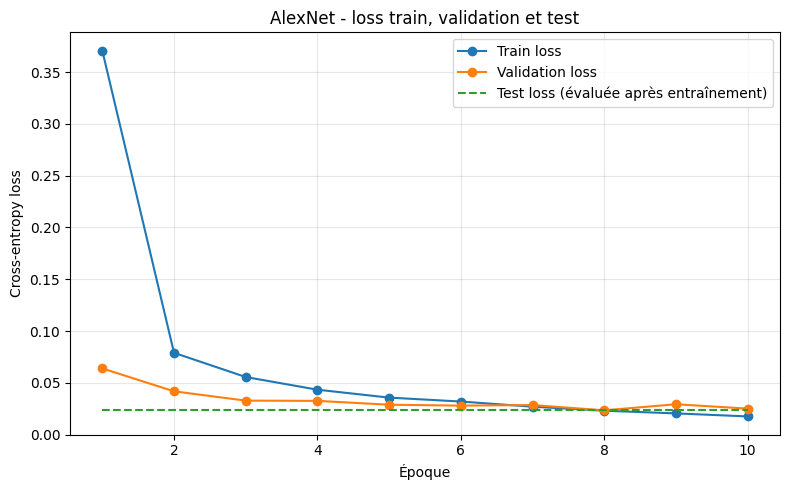

In [8]:
# Les trois courbes : test loss est une constante car le jeu test est évalué une fois après l’entraînement.
epochs=[r["epoch"] for r in history]
train_losses=[r["train_loss"] for r in history]
val_losses=[r["val_loss"] for r in history]
test_losses=[test_loss]*len(epochs)
plt.figure(figsize=(8,5))
plt.plot(epochs,train_losses,marker="o",label="Train loss")
plt.plot(epochs,val_losses,marker="o",label="Validation loss")
plt.plot(epochs,test_losses,linestyle="--",label="Test loss (évaluée après entraînement)")
plt.xlabel("Époque"); plt.ylabel("Cross-entropy loss"); plt.title("AlexNet - loss train, validation et test")
plt.grid(True,alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

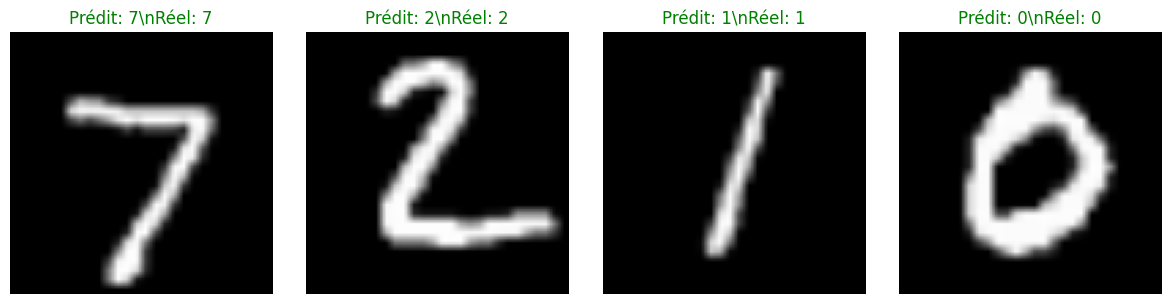

Checkpoint: /kaggle/working/mnist_alexnet_best.pth


In [9]:
# Quatre prédictions test
xs,ys=next(iter(test_loader))
with torch.no_grad(): preds=model(xs[:4].to(device)).argmax(1).cpu()
fig,axs=plt.subplots(1,4,figsize=(12,3))
for ax,x,y,p in zip(axs,xs[:4],ys[:4],preds):
    ax.imshow((x*std+mean).clamp(0,1).permute(1,2,0))
    ax.set_title(f"Prédit: {p.item()}\\nRéel: {y.item()}",color="green" if p.item()==y.item() else "red")
    ax.axis("off")
plt.tight_layout(); plt.show()
print("Checkpoint: /kaggle/working/mnist_alexnet_best.pth")

## Réutiliser le checkpoint
Le meilleur modèle est enregistré dans /kaggle/working/mnist_alexnet_best.pth. Après Save Version, il figure dans les sorties Kaggle. La ligne test du graphique est horizontale : la test loss est calculée après entraînement et n’est pas recalculée à chaque époque, afin de garder le test indépendant.